# NB Pipeline explanatory notebooks
## Notebook 1: Exploratory Data Analysis
The aim of this series of notebooks is to explain the functionality of the Negative Bionomial model piepline and explain justify the different desing choices made.
In this first notebook we will perform exoloratory data anlysis of both the donor and patient data and perform a number of Quality Control (QC) steps to clean the datasets for further usage.


In [1]:
import sys
sys.path.insert(0, '..')

import warnings
from itertools import combinations, permutations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import list_subjects, load_group, load_subject, sample_qc, drop_failed_samples
from tcr_pipeline.utils import summarize_nan_trajectories
from tcr_pipeline import nb_glm as nb

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 160)

# plotting: one fixed colour per donor (same colour in every figure), recessive axes
DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY = '#8a8984'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#3d3c39', 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})

## 1.1 What does the data contain?
Each row is one clonotype in one sample:

* `count` — reads assigned to the clonotype. The data are **RNA**-based, so a read count
  does not map one-to-one to the number of cells detected (as opposed to **DNA** sampling), but rather how many TCR transcripts the clonotype has. One cell may provide several TCR transcripts. 
* `freq` - the clone's share of the sample's in-frame reads (in %).
* `D_t` - the sample's in-frame depth.

The data frames we will use from now on have already been procesed to only use In-Frame clonotypes and anonymized.  

#### Structure of the processed data
The data is stored in *subjects*_clono where *subjects* is either donors or patients. The structure of the folder is as following:
```
subjects_clono/
├── counts/
│   ├── subject_1.csv
│   ├── subject_2.csv
│   └── ...
├── sequences/
│   ├── subject_1_sequences.csv
|   ├── subject_2_sequences.csv
│   └── ...
├── subjects.txt
├── sample_sizes.csv
└── README.md
```
`subjects.txt` contains the names of all the subjects present in the folder.

Each clone gets identified by the key [`CDR3_sequence`, `TRBV`,`TRBJ`] and gets assinged a clone identifier (`1`, `2`, …) in order or appearance. Clone identifiers (`1`, `2`, …) are assigned **per person**. The same identifier in two people is not the same clone. The mapping of keys->identifiers per subject are found in the sequences folder.

The `counts/` folder contains the data frame with the counts per anonymized clonotype. 

`sample_sizes.csv` contains the sample size per subject and day.

In `data_io.py` we provide a series of helper functions to easily load the dataframes, either per donor/patient or all donors together, with several options to choose which columns to load to not overload memory. **The helpers only help this specific saving format**

In [2]:
healthy_df = load_group("donors", with_freq=True, with_D_t=True)

In [3]:
patient_df = load_group("patients", with_freq=True, with_D_t=True)

In [4]:
healthy_df.head()

,patient,day,clono,count,D_t,freq
0,HD106_SEQTR,0,1,226089,21258772,0.010635
1,HD106_SEQTR,0,2,159926,21258772,0.007523
2,HD106_SEQTR,0,3,141200,21258772,0.006642
3,HD106_SEQTR,0,4,82582,21258772,0.003885
4,HD106_SEQTR,0,5,70402,21258772,0.003312


In [22]:
g = healthy_df.groupby(["patient", "day"], observed=True)
samples_h =g.agg(D_t=('D_t', 'first'), n_clones=('clono', 'size'), top_clone_share=('freq', 'max'))
samples_h['top_clone_share'] = samples_h['top_clone_share']

In [23]:
per_donor = samples_h.groupby('patient').agg(
    n_samples=('D_t', 'size'),
    days=('D_t', lambda s: ', '.join(map(str, s.index.get_level_values('day')))),
    depth_M=('D_t', lambda s: f"{s.min()/1e6:.1f}–{s.max()/1e6:.1f}"),
    clones_k=('n_clones', lambda s: f"{s.min()/1e3:.1f}–{s.max()/1e3:.0f}"),
    top_clone=('top_clone_share', lambda s: f"{s.min():.3f}–{s.max():.3f}"))
display(per_donor)

,n_samples,days,depth_M,clones_k,top_clone
patient,,,,,
HD106_SEQTR,4,"0, 46, 82, 131",13.5–21.3,794.9–1162,0.009–0.012
HD197_SEQTR,4,"0, 46, 82, 131",15.5–18.3,926.2–1130,0.006–0.011
HDBR01_SEQTR_ReSeq,4,"0, 21, 42, 126",10.4–21.7,420.2–660,0.003–0.003
HDBR02_SEQTR_ReSeq,3,"0, 48, 71",5.5–9.0,219.9–353,0.154–0.252
HDBR03_SEQTR_ReSeq,5,"0, 21, 35, 66, 84",5.1–10.8,311.6–453,0.016–0.039
HDBR06_SEQTR_ReSeq,4,"0, 21, 82, 105",5.1–11.7,6.7–438,0.035–0.242


In [40]:
DONORS = list_subjects("donors")
COLOR = dict(zip(DONORS, DONOR_COLORS))

In [41]:
DONORS

['HD106_SEQTR',
 'HD197_SEQTR',
 'HDBR01_SEQTR_ReSeq',
 'HDBR02_SEQTR_ReSeq',
 'HDBR03_SEQTR_ReSeq',
 'HDBR06_SEQTR_ReSeq']

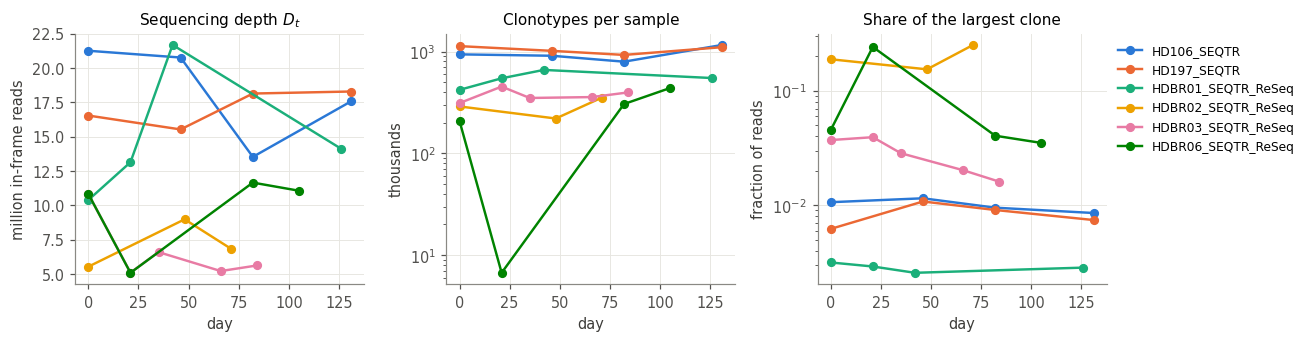

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for p in DONORS:
    s = samples_h.loc[p]
    kw = dict(color=COLOR[p], marker='o', label = p)
    axes[0].plot(s.index, s['D_t'] / 1e6, **kw)
    axes[1].plot(s.index, s['n_clones'] / 1e3, **kw)
    axes[2].plot(s.index, s['top_clone_share'], **kw)
axes[0].set(title='Sequencing depth $D_t$', xlabel='day', ylabel='million in-frame reads')
axes[1].set(title='Clonotypes per sample', xlabel='day', ylabel='thousands', yscale='log')
axes[2].set(title='Share of the largest clone', xlabel='day', ylabel='fraction of reads',
            yscale='log')
axes[2].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()

From this table and figures, we can notice several features worth mentioning:

* Depth varies about 4-fold across samples (4.9–21.3 M reads), within as well as between donors. A clone's read count is only comparable across samples after dividing by depth, so every model below uses an offset factor.
* Donors differ far more in repertoire structure than in depth: from about 43 k to 214 k clonotypes per sample (one failed sample aside), and a largest clone holding from 0.3 % (HDBR01) to 26 % (HDBR02) of reads. Any per-sample quality criterion therefore has to be relative to the same person.
* One sample is obviously different from everything else: HDBR06 day 21, with 706 clonotypes against 43–85 k in the donor's other samples

HD106_SEQTR 0 | clonotypes: 938259 | with count > K: 86192 | singletons: 482715
HDBR03_SEQTR_ReSeq 21 | clonotypes: 452593 | with count > K: 10249 | singletons: 204318


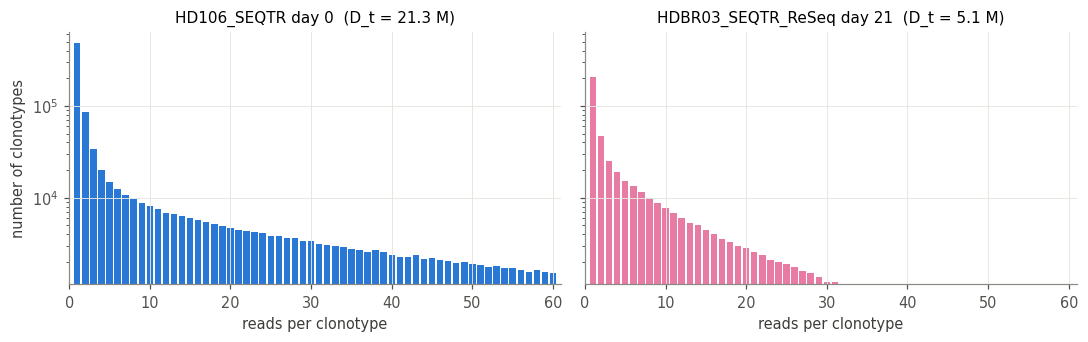

In [48]:
K = 60                                   # largest read count shown; raise it to see more of the tail
k = np.arange(1, K + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (p, day) in zip(axes, [("HD106_SEQTR", 0), ("HDBR03_SEQTR_ReSeq", 21)]):
    s = healthy_df[(healthy_df["patient"] == p) & (healthy_df["day"] == day)]
    n_k = s["count"].value_counts().reindex(k, fill_value=0)
    ax.bar(k, n_k.values, width=0.8, color=COLOR[p])
    ax.set(title=f'{p} day {day}  (D_t = {s["D_t"].iloc[0]/1e6:.1f} M)',
           xlabel="reads per clonotype", yscale="log")
    ax.set_xlim(0, K + 1)
    print(p, day, "| clonotypes:", len(s), "| with count > K:", int((s["count"] > K).sum()),
          "| singletons:", int(n_k.loc[1]))
axes[0].set_ylabel("number of clonotypes")
fig.tight_layout()

In all 60 samples (24 donor, 36 patient) the smallest observed count is 1, so no detection threshold was applied to the raw tables and $c_t = 1$ throughout. A count of 0 means no read was observed. It is a sampling outcome, not evidence that the clone was absent. This shapes the likelihood in two ways:

* 1. Observed counts are conditional on detection. Clones with expected count near 1 are reported only when they fluctuate upwards. Fitting the noise on detected counts uses the zero-truncated NB, $P(X = x \mid X \ge 1) = f(x)/(1 - f(0))$, where a higher truncation point $c \ge 1$ can be used to exclude the low-count range dominated by error variants.
* 2. A missing clone is an NB zero. It contributes $P(X = 0 \mid \mu, \phi)$ with $\mu = D_t f$, so the same clone at the same frequency is more likely to be missing in a shallow sample than in a deep one. The depth dependence enters through $D_t$, not through a sample-specific threshold.

## 1.3 Dropouts
Dropouts/Nans/Non-detections are an essential part of modeling the trajectories. In the following cells, we will better understand the nature and frequency of dropouts in the datasets.

In [49]:
h_ok = summarize_nan_trajectories(healthy_df)
h_ok.head()

,patient,n_timepoints,n_clonotypes,n_missing,n_clono,pct_clono
0,HD106_SEQTR,4,3551504,0,24641,0.69
1,HD106_SEQTR,4,3551504,1,35893,1.01
2,HD106_SEQTR,4,3551504,2,106705,3.00
3,HD106_SEQTR,4,3551504,3,3384265,95.29
4,HD197_SEQTR,4,3816358,0,40111,1.05


In [64]:
p_ok = summarize_nan_trajectories(patient_df)
p_ok.head()

,patient,n_timepoints,n_clonotypes,n_missing,n_clono,pct_clono
0,BR032,6,3144106,0,21,0.00
1,BR032,6,3144106,1,4970,0.16
2,BR032,6,3144106,2,8687,0.28
3,BR032,6,3144106,3,18898,0.60
4,BR032,6,3144106,4,69932,2.22


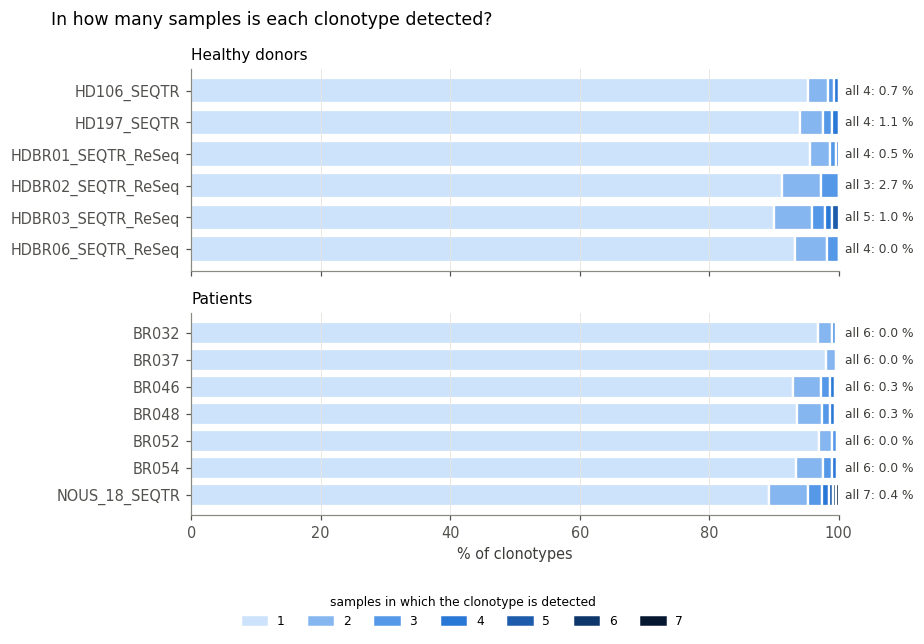

In [69]:
#Examining the distribution of clonotypes detected in how many samples for healthy donors and patients. The bar plots show the percentage of clonotypes detected in 1, 2, 3, 4, 5 or 6 samples. The text on the right indicates the percentage of clonotypes detected in all samples for each donor/patient.
from tcr_pipeline.utils import summarize_nan_trajectories

nan_tabs = {'Healthy donors': h_ok,
            'Patients': p_ok}
# one blue ramp for both panels: light = seen once, dark = seen in 6 samples
SEQ = {1: '#cde2fb', 2: '#86b6ef', 3: '#5598e7', 4: '#2a78d6', 5: '#1c5cab', 6: '#0d366b', 7: '#061830' }

fig, axes = plt.subplots(2, 1, figsize=(8.5, 5.6), sharex=True)
for ax, (title, tab) in zip(axes, nan_tabs.items()):
    t = tab.assign(n_detected=tab['n_timepoints'] - tab['n_missing'])
    wide = (t.pivot(index='patient', columns='n_detected', values='pct_clono')
              .fillna(0).sort_index(ascending=False))
    left = np.zeros(len(wide))
    for k in wide.columns:
        ax.barh([p for p in wide.index], wide[k], left=left, color=SEQ[k],
                edgecolor='white', linewidth=1.5)
        left += wide[k].to_numpy()
    for y, p in enumerate(wide.index):        # label the 'seen in every sample' share
        T = int(t.loc[t['patient'] == p, 'n_timepoints'].iloc[0])
        ax.text(101, y, f"all {T}: {wide.loc[p, T]:.1f} %", va='center', fontsize=8,
                color='#3d3c39')
    ax.set_title(title, loc='left')
    ax.grid(axis='y', visible=False)
axes[-1].set(xlim=(0, 100), xlabel='% of clonotypes')
handles = [plt.Rectangle((0, 0), 1, 1, color=SEQ[k]) for k in SEQ]
fig.legend(handles, list(SEQ), title='samples in which the clonotype is detected', ncol=7,
           fontsize=8, title_fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.04),
           frameon=False)
fig.suptitle('In how many samples is each clonotype detected?', x=0.06, ha='left')
fig.tight_layout(rect=(0, 0.06, 1, 1))

**What this shows**

84–96 % of clonotypes are detected in a single sample, and only 0–5 % in every sample. A missing sample is therefore the normal state of a clonotype, not a rare event, and absence cannot be read as disappearance. 
It also means that most clonotypes carry too little information to be used. A clonotype seen once has no trajectory, **whatever the model**. Only 3.0–7.6 % of
donor clonotypes can be used for null calibration and only  1.0–5.4 % of patient clonotypes (not shown in this notebook) can be tested for detection.

## 1.4 Clone-Size distribution
The next step to understand the composition of the data, is to study the frequency distribution of the clones. 

In [56]:
f = healthy_df.assign(freq=healthy_df['count'] / healthy_df['D_t'])
band = pd.cut(f['freq'], [0, 1e-5, 1e-4, 1],
              labels=['1e-6 – 1e-5', '1e-5 – 1e-4', '≥ 1e-4'], right=False)
bands = (f.groupby(['patient', band], observed=False)
          .agg(clones=('clono', 'size'), reads=('count', 'sum')))
bands = bands / bands.groupby(level=0).transform('sum')
display(bands)

clones     reads
patient            freq                           
HD106_SEQTR        1e-6 – 1e-5  0.987038  0.643333
                   1e-5 – 1e-4  0.012646  0.236242
                   ≥ 1e-4       0.000317  0.120425
HD197_SEQTR        1e-6 – 1e-5  0.990254  0.636473
                   1e-5 – 1e-4  0.009315  0.206925
                   ≥ 1e-4       0.000431  0.156601
HDBR01_SEQTR_ReSeq 1e-6 – 1e-5  0.951092  0.404855
                   1e-5 – 1e-4  0.048393  0.537028
                   ≥ 1e-4       0.000515  0.058116
HDBR02_SEQTR_ReSeq 1e-6 – 1e-5  0.960176  0.258915
                   1e-5 – 1e-4  0.038248  0.254723
                   ≥ 1e-4       0.001576  0.486362
HDBR03_SEQTR_ReSeq 1e-6 – 1e-5  0.950473  0.358453
                   1e-5 – 1e-4  0.047981  0.408646
                   ≥ 1e-4       0.001546  0.232901
HDBR06_SEQTR_ReSeq 1e-6 – 1e-5  0.939957  0.190154
                   1e-5 – 1e-4  0.058039  0.381095
                   ≥ 1e-4       0.002004  0.428751

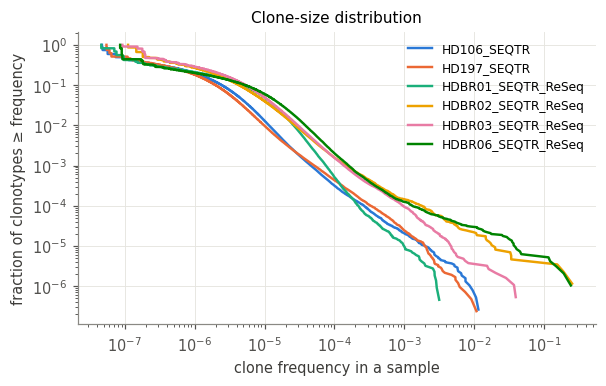

In [58]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for p in DONORS:
    x = np.sort(f.loc[f['patient'] == p, 'freq'].to_numpy())
    ccdf = 1 - np.arange(len(x)) / len(x)
    ax.plot(x, ccdf, color=COLOR[p], label=p)
ax.set(xscale='log', yscale='log', xlabel='clone frequency in a sample',
       ylabel='fraction of clonotypes ≥ frequency',
       title='Clone-size distribution')
ax.legend(fontsize=8)
fig.tight_layout()

**What this shows.** The repertoire is extremely heavy-tailed. Most clones have low frequency however they take up a relatively small percentage of the total read count. As such, it could be reasonable to indtroduc a frequency cutoff for both the computation of the overdispersion and the tested patient trajectories. The implementation of said cutoff and its value will be studied in further notebooks using simulated data.

## 1.5 Sample QC: which samples are failed libraries?

One crucial step before performing infernce is filtering out failed samples which contaminate and bias the results. This step is knows as Quality Control (QC). We filter based on different metric for which we set arbitrary thresholds.

Section 1.1 showed that donors differ by an order of magnitude in diversity and
clonality, so absolute thresholds would flag whole people. Each metric is instead
expressed **relative to the median of the same person's other samples** (`*_rel` = 1 means
typical for that person):

| metric | what a failed library looks like | fails if |
|---|---|---|
| `n_clones_rel` — clonotypes reported | to few clonotypes | < 0.2 |
| `top_share_rel` — share of the largest clone | one clone dominates PCR reads | > 5 |
| `reads_per_clone_rel` — reads / clonotype | reads spread over few clones (library size aware version of `n_clones_rel`) | > 5 |

Anchor clones: detected in **all** the person's other samples with mean frequency ≥ 1e-5.
A sample is **dropped if it fails at least two** criteria; a single failure is flagged
for review but kept.

In [72]:
qc_d = sample_qc(healthy_df)
qc_p = sample_qc(patient_df)
qc = pd.concat([qc_d.assign(cohort='donor'), qc_p.assign(cohort='patient')], ignore_index=True)
metrics = {'n_clones_rel': ('< 0.2', 0.2), 'top_share_rel': ('> 5', 5),
           'reads_per_clone_rel': ('> 5', 5)}
show = ['cohort', 'patient', 'day', *metrics, 'n_fails', 'drop', 'review']

def failed_on(row):
    """Names of the criteria this sample fails."""
    return ', '.join(m.replace('_rel', '') for m, (rule, thr) in metrics.items()
                     if (row[m] < thr if rule.startswith('<') else row[m] > thr))

def highlight_fails(col):
    """Red cell where the value is on the failing side of its threshold."""
    rule, thr = metrics[col.name]
    bad = col < thr if rule.startswith('<') else col > thr
    return ['background-color: #f8d7d6; color: #8c1d1d; font-weight: bold' if b else ''
            for b in bad]

flagged = qc.loc[qc['n_fails'] > 0, show].copy()
flagged.insert(3, 'failed on', flagged.apply(failed_on, axis=1))

display(flagged.style
        .apply(highlight_fails, subset=list(metrics))
        .format({m: '{:.3f}' for m in metrics})
        .hide(axis='index'))

cohort,patient,day,failed on,n_clones_rel,top_share_rel,reads_per_clone_rel,n_fails,drop,review
donor,HDBR06_SEQTR_ReSeq,21,"n_clones, top_share, reads_per_clone",0.022,5.974,19.832,3,True,False
patient,BR037,28,top_share,1.138,12.149,0.583,1,False,True
patient,BR046,120,top_share,0.734,6.688,1.520,1,False,True
patient,BR052,164,"n_clones, reads_per_clone",0.048,1.128,10.355,2,True,False
patient,BR052,192,"n_clones, reads_per_clone",0.100,0.808,5.620,2,True,False
patient,BR054,141,top_share,0.264,7.813,2.069,1,False,True


One donor and four different patient samples fail, two of the patients sample belonging to the same patient. Two other samples get flagged for review.

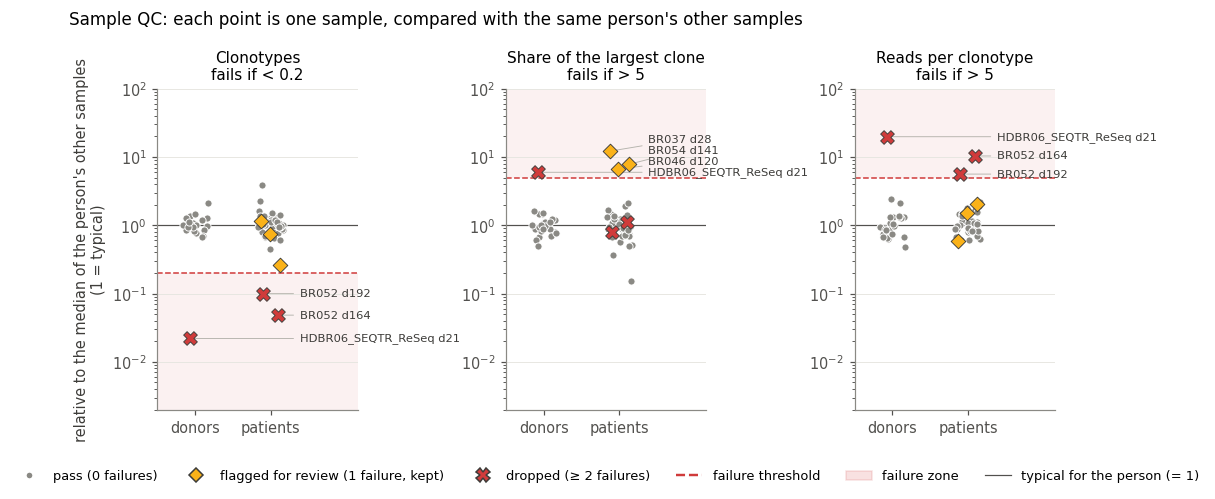

In [74]:
TITLES = {'n_clones_rel': 'Clonotypes', 'top_share_rel': 'Share of the largest clone',
          'reads_per_clone_rel': 'Reads per clonotype'}
STATUS = {  # marker, colour, size, label
    'pass':    ('o', '#8a8984', 22, 'pass (0 failures)'),
    'review':  ('D', '#fab219', 46, 'flagged for review (1 failure, kept)'),
    'dropped': ('X', '#d03b3b', 80, 'dropped (≥ 2 failures)')}
qc['status'] = np.select([qc['drop'], qc['n_fails'] == 1], ['dropped', 'review'], 'pass')
qc['label'] = [f"{p} d{d}" for p, d in zip(qc['patient'], qc['day'])]
rs = np.random.default_rng(1)
qc['x'] = (qc['cohort'] == 'patient').astype(float) + rs.uniform(-0.17, 0.17, len(qc))
YLIM = (2e-3, 100)

fig, axes = plt.subplots(1, 3, figsize=(10, 4.4))
for ax, (m, (rule, thr)) in zip(axes, metrics.items()):
    low_fails = rule.startswith('<')
    if low_fails:                                      # failure zone, shaded
        ax.axhspan(YLIM[0], thr, color='#d03b3b', alpha=0.07, lw=0)
    else:
        ax.axhspan(thr, YLIM[1], color='#d03b3b', alpha=0.07, lw=0)
    ax.axhline(thr, color='#d03b3b', lw=1, ls='--')
    ax.axhline(1, color='#52514e', lw=0.8)
    for st, (mk, col, sz, _) in STATUS.items():
        s = qc[qc['status'] == st]
        ax.scatter(s['x'], s[m].clip(*YLIM), marker=mk, s=sz, color=col,
                   edgecolor='white' if st == 'pass' else '#3d3c39', linewidth=0.6,
                   zorder=3 if st == 'pass' else 4)
    # name the samples that fail THIS criterion (labels kept apart, with leader lines)
    fails = qc[(qc[m] < thr) if low_fails else (qc[m] > thr)].sort_values(m)
    ly = np.log10(fails[m].clip(*YLIM).to_numpy())
    for i in range(1, len(ly)):                      # keep labels >= 0.16 decades apart
        ly[i] = max(ly[i], ly[i - 1] + 0.16)
    for (_, r), y in zip(fails.iterrows(), ly):
        ax.annotate(r['label'], xy=(r['x'], np.clip(r[m], *YLIM)), xytext=(1.38, 10 ** y),
                    textcoords='data', va='center', fontsize=7.5, color='#3d3c39',
                    arrowprops=dict(arrowstyle='-', color='#b5b4ad', lw=0.6))
    ax.set(yscale='log', ylim=YLIM, xlim=(-0.5, 2.15), xticks=[0, 1],
           xticklabels=['donors', 'patients'], title=f'{TITLES[m]}\nfails if {rule}')
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel("relative to the median of the person's other samples\n(1 = typical)")
handles = [plt.Line2D([], [], marker=mk, ls='', color=col, markersize=np.sqrt(sz),
                      markeredgecolor='white' if st == 'pass' else '#3d3c39', label=lab)
           for st, (mk, col, sz, lab) in STATUS.items()]
handles += [plt.Line2D([], [], color='#d03b3b', ls='--', label='failure threshold'),
            plt.Rectangle((0, 0), 1, 1, color='#d03b3b', alpha=0.15, label='failure zone'),
            plt.Line2D([], [], color='#52514e', lw=0.8, label='typical for the person (= 1)')]
fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=8.5, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Sample QC: each point is one sample, compared with the same person's other samples",
             x=0.01, ha='left', fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 1))

**What this shows.**

* Over the donor samples that pass QC, every metric stays within a factor of about 3 of
  the person's typical value (`n_clones_rel` 0.59–1.97, `top_share_rel` 0.51–1.66,
  `reads_per_clone_rel` 0.50–3.11). The thresholds sit outside
  that range with a margin, so ordinary sample-to-sample variation never fails.
* **HDBR06 day 21** fails all three, by one to two orders of magnitude: 1 % of the donor's
  usual clonotypes, 42× the reads per clonotype, and it recaptures 0.9 % of the anchor
  clones. That is a failed library, not biology, and it is the only donor sample removed.
* In the patients, the same rule removes *BR052 days 164 and 192**, each fails two or more criteria together. The fact that both samples come from the same question can be problematic, and should be adressed with more detail as it could be genuine biology that we are flagging.
* **Why two failures and not one.** The single-failure samples are exactly the cases we
  must keep. BR046 day 120 has a largest clone 6.5× its usual share wich can be a large clonal
  expansion, i.e. the signal the pipeline is looking for.

There is geniune criticism to be made about the selected metrics used for QC, and the cirterias for flagging failed libraries could and should be revised in the future, potentially supported by further data. As it stands, we correctly flag **HDBR06 day 21** as a failed library, which we expected to fail under other considerable metrics. This is the most imporant drop, as donors are used for the Null-Calibration and directly influence the tests performed on the patient trajectories.

Patient **BR052** had two dropped libraries, however, the results of one patient do not influence those of another, so these libraries can be flagged instead of dropped and still be anaylsed downstream, with careful monitoring of the results.